In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
torch.manual_seed(42)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device( 'cpu')

# PINN model
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.net = nn.Sequential()
        for i in range(len(layers) - 1):
            self.net.add_module(f"layer{i}", nn.Linear(layers[i], layers[i + 1]))
            if i < len(layers) - 2:
                self.net.add_module(f"tanh{i}", nn.Tanh())

    def forward(self, x):
        return self.net(x)

In [ ]:
q_0=0.015
l=10
EI=20.83

# Right-hand side of Poisson equation
def f(x):
    return q_0*torch.sin(np.pi*x/l)

# PDE residual
def pde_loss(model, X):
    X.requires_grad_(True)
    u = model(X)
    u_x = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0]
    u_xxx = torch.autograd.grad(u_xx, X, torch.ones_like(u_x), create_graph=True)[0]
    u_xxxx = torch.autograd.grad(u_xxx, X, torch.ones_like(u_x), create_graph=True)[0]
    
    source = f(X)
    return torch.mean((source-u_xxxx*EI)**2)

# Boundary loss
def boundary_loss_D(model, Xb):
    u=model(Xb)
    
    return torch.mean(u**2)

def boundary_loss_N(model, Xb):

    Xb.requires_grad_(True)
    u=model(Xb)
    u_x = torch.autograd.grad(u, Xb, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, Xb, torch.ones_like(u_x), create_graph=True)[0]

    return torch.mean(u_xx**2)


# Generate collocation and boundary points
def generate_points(n_interior):
    # Interior points
    xy_in = torch.linspace(0,10,n_interior).reshape(n_interior,1).to(device)
    
    xy_b = torch.tensor([[0],[10]], dtype=torch.float32).to(device)
    return xy_in, xy_b

# Train the model
###########Changes############
# layers = [2, 20, 20, 20, 1]
# layers = [2, 64, 64, 1]
layers = [1, 120, 120,  1]
###########Changes############

model = PINN(layers).to(device)
model.to(device)


In [70]:
# we run and balance the terms, we need to balance the pde and Neuman loss(loss_in, loss_bn) to 10-7 and Dirichlet(loss_bd) to 10-9

model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)

###########Changes############
X_in, X_b = generate_points(20000)
# X_in, X_b = generate_points(5000, 50)
###########Changes############
# loss_vec = []
for epoch in range(60000):

    optimizer.zero_grad()

    loss_in = pde_loss(model, X_in)
    loss_bd = boundary_loss_D(model, X_b)
    loss_bn = boundary_loss_N(model, X_b)
    loss = 100*loss_in + 10*loss_bd + 100*loss_bn

    loss.backward()
    optimizer.step()

    loss_vec.append(loss.item())
    if epoch % 300 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item()}")
    # if epoch==0:
    #     break  




Epoch 0, Loss: 4.990812885807827e-05
Epoch 300, Loss: 4.987569627701305e-05
Epoch 600, Loss: 4.986501153325662e-05
Epoch 900, Loss: 4.9849320930661634e-05
Epoch 1200, Loss: 4.9829919589683414e-05
Epoch 1500, Loss: 4.98051340400707e-05
Epoch 1800, Loss: 4.977536082151346e-05
Epoch 2100, Loss: 4.974018520442769e-05
Epoch 2400, Loss: 4.969752626493573e-05
Epoch 2700, Loss: 4.964718027622439e-05
Epoch 3000, Loss: 4.961805825587362e-05
Epoch 3300, Loss: 4.96053762617521e-05
Epoch 3600, Loss: 4.9594062147662044e-05
Epoch 3900, Loss: 4.9582013161852956e-05
Epoch 4200, Loss: 4.9567239329917356e-05
Epoch 4500, Loss: 4.9550704716239125e-05
Epoch 4800, Loss: 4.9529095122125e-05
Epoch 5100, Loss: 4.950517904944718e-05
Epoch 5400, Loss: 4.947881825501099e-05
Epoch 5700, Loss: 4.9446280172560364e-05
Epoch 6000, Loss: 4.940890721627511e-05
Epoch 6300, Loss: 4.93654515594244e-05
Epoch 6600, Loss: 4.931496368953958e-05
Epoch 6900, Loss: 4.925523535348475e-05
Epoch 7200, Loss: 0.00016895978478714824
Epo

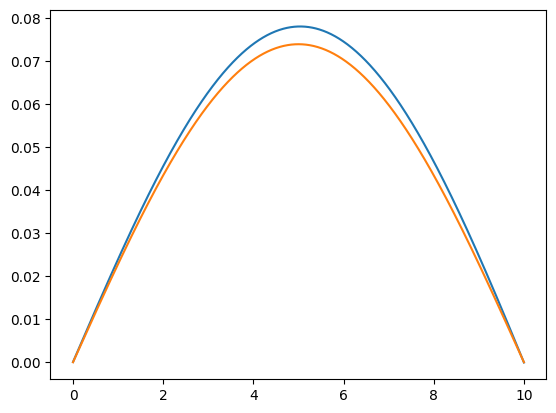

In [69]:
x = torch.linspace(0,10,1000).reshape(1000,1)
u_exact = q_0*l**4/(np.pi**4*EI)*np.sin(np.pi*x/l)
model.cpu()
plt.plot(x,model(x).detach().numpy() )
plt.plot(x,u_exact )


In [67]:

torch.save(model.state_dict(),'./results/beam/model_pinn.pth')